# Tuning γ and the green-up threshold

The strategy has two settings we haven't pinned down from data yet:

- **γ (`gamma`), risk aversion.** In the A–S quotes it sets how hard we lean against inventory and how much extra spread we ask for carrying risk:
$$r = S - q\,\gamma\,\sigma^2(T-t), \qquad \delta = \tfrac12\gamma\,\sigma^2(T-t) + \frac{1}{\gamma}\ln\!\left(1+\frac{\gamma}{k}\right)$$
  A small γ quotes close and lets inventory build. A large γ quotes wide and sheds inventory quickly, trading less.
- **The green-up threshold (`greenup_min_units`).** At $T$ = 30 s before the off we stop quoting and flatten every position at least this big, crossing the spread to do it. Anything smaller is left to settle on the race result.

We tune both on the **validation days, 1–14 February**, with everything else frozen: σ², the queue-aware $k$, the adverse-selection model, a quote size of 10 contracts, a position cap of 50, 4% commission and 0.2 s latency. March stays untouched for the final test.

**The grid**

- γ: 0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 0.75, 1, 1.5, 2, 3. These are roughly evenly spaced on a log scale, so every chart shows γ on a log axis.
- Threshold: 0 (flatten everything), 1, 2.5, 5, 10, 20, or never flatten. Positions are in contracts: a contract pays $1 if the runner wins, and one full quote is 10.

**How we choose.** Profit over the two weeks, with 95% intervals from resampling races, as in the σ² and $k$ notebooks. We favour the middle of a flat region over a single sharp peak, and a setting only counts as better if it is better consistently, not through a few lucky races.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
from matplotlib.ticker import FixedLocator, NullLocator

# Project root = the folder that holds research/ (works whether this runs from research/ or the root)
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "research" / "results").exists())
RESULTS = ROOT / "research" / "results" / "hyperparameter_grid"   # one backtest per gamma, from the runs below

GAMMAS = [0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 0.75, 1, 1.5, 2, 3]
THRESHOLDS = [0, 1, 2.5, 5, 10, 20, np.inf]          # greenup_min_units, in contracts; inf = never flatten
COMMISSION = 0.04                                    # Betfair commission on each market's net winnings
N_BOOT = 1000
rng = np.random.default_rng(42)

# Chart style: blue = the settings we choose, greys for everything else, a light hairline grid
BLUE = "#2a78d6"
GREY = "#898781"
LIGHT = "#c3c2b7"
INK, INK_2 = "#0b0b0b", "#52514e"
%config InlineBackend.figure_format = "retina"
plt.rcParams.update({
    "figure.figsize": (8, 4.2), "figure.facecolor": "white", "axes.facecolor": "white",
    "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "Helvetica Neue", "Arial", "DejaVu Sans"],
    "font.size": 10, "text.color": INK, "axes.labelcolor": INK_2, "axes.labelpad": 6,
    "xtick.color": LIGHT, "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2, "ytick.major.size": 0,
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "axes.edgecolor": LIGHT, "axes.linewidth": 0.8,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#e1e0d9", "grid.linewidth": 0.8,
    "lines.linewidth": 2, "lines.markersize": 7, "lines.markeredgewidth": 1.5, "lines.markeredgecolor": "white",
    "legend.frameon": False, "legend.fontsize": 9.5,
})


def titles(ax, title, subtitle, gap=10):
    # A bold headline that states the finding, then a smaller line saying what is plotted
    note = ax.annotate(subtitle, (0, 1), xycoords="axes fraction", xytext=(0, gap), textcoords="offset points",
                       fontsize=9.5, color=INK_2, va="bottom", linespacing=1.45)
    head = ax.set_title(title, loc="left", fontsize=12.5, fontweight="semibold",
                        pad=gap + 6 + 14 * (subtitle.count("\n") + 1))
    note.set_in_layout(False)
    head.set_in_layout(False)


def legend(ax, **kwargs):
    # A legend whose keys drop the white ring around markers (on a short key it makes a line look dashed)
    for key in ax.legend(**kwargs).legend_handles:
        if isinstance(key, Line2D):
            key.set_markeredgewidth(0)


def gamma_axis(ax):
    # gamma on a log scale, with a tick at every value we tested
    ax.set_xscale("log")
    ax.xaxis.set_major_locator(FixedLocator(GAMMAS))
    ax.xaxis.set_minor_locator(NullLocator())
    ax.set_xticklabels([f"{g:g}" for g in GAMMAS])
    ax.set_xlabel("γ (log scale)")


def threshold_name(t):
    return "never" if np.isinf(t) else f"{t:g}"


print(f"{len(GAMMAS)} values of gamma x {len(THRESHOLDS)} green-up thresholds, on 1-14 February")

11 values of gamma x 7 green-up thresholds, on 1-14 February


## Step 1: The backtests, and a shortcut for the threshold

Each γ was backtested once over 1–14 February with `scripts/run_backtest.py`, flattening every position at $T$ (a threshold of 0). The outputs are in `research/results/hyperparameter_grid/`.

The threshold doesn't need a backtest of its own. It only matters at $T$, when quoting has already stopped, so everything before that is the same whatever the threshold. A higher threshold just means some of the green-up bets are never placed: the ones on runners whose position was below the threshold when the green-up order went in. So we can take each run, drop those bets, and settle each market again, charging 4% commission on its net winnings.

**Checking the shortcut.** A threshold of 0 must reproduce each run exactly. We also ran two real backtests to compare with: γ = 1 with a threshold of 10, and the setting we end up choosing, γ = 0.5 with a threshold of 1.

In [2]:
def load_run(folder):
    # Every fill of one backtest, with its settled profit and the position before it
    fills = pd.read_csv(folder / "fills.csv", dtype={"market_id": str})
    bets = pd.read_csv(folder / "bets.csv", dtype={"market_id": str})     # the same fills, in the same order
    assert (fills["market_id"] == bets["market_id"]).all() and np.allclose(fills["stake"], bets["stake"])
    fills["profit"] = bets["gross_pnl"].to_numpy()                            # before commission
    runner = [fills["market_id"], fills["selection_id"]]
    fills["q_before"] = fills.groupby(runner)["q_after"].shift(fill_value=0.0)
    # One green-up order can fill in several pieces; the strategy decided on the position before the first one
    fills["q_at_order"] = fills.groupby([*runner, fills["publish_time"], fills["tag"]])["q_before"].transform("first")
    return fills


def market_profit(fills, threshold):
    # Each market's profit after commission, as if green-ups had stopped below the threshold
    green = fills["tag"] == "greenup"
    skipped = green & (fills["q_at_order"].abs() < threshold)
    skipped = skipped.astype(int).groupby([fills["market_id"], fills["selection_id"]]).cummax().astype(bool) & green
    gross = fills.loc[~skipped].groupby("market_id")["profit"].sum()
    return gross - COMMISSION * gross.clip(lower=0)


runs = {g: load_run(RESULTS / f"gamma_{g:g}") for g in GAMMAS}

for g, fills in runs.items():                     # a threshold of 0 is exactly the backtest
    saved = pd.read_csv(RESULTS / f"gamma_{g:g}" / "markets.csv", dtype={"market_id": str}).set_index("market_id")
    assert np.allclose(market_profit(fills, 0).reindex(saved.index), saved["net_pnl"])

print(f"Threshold 0 reproduces all {len(runs)} backtests exactly")
for g, t in [(1, 10), (0.5, 1)]:                  # two real backtests at other thresholds
    real = pd.read_csv(RESULTS / f"check_gamma_{g:g}_greenup_{t:g}" / "markets.csv",
                       dtype={"market_id": str}).set_index("market_id")["net_pnl"]
    shortcut = market_profit(runs[g], t).reindex(real.index, fill_value=0.0)
    differ = (shortcut - real).abs() > 0.01
    print(f"gamma = {g:g}, threshold {t:g}: shortcut ${shortcut.sum():.2f}, real backtest ${real.sum():.2f} "
          f"(different in {differ.sum()} of {len(real):,} races)")

Threshold 0 reproduces all 11 backtests exactly
gamma = 1, threshold 10: shortcut $253.03, real backtest $269.79 (different in 6 of 1,158 races)
gamma = 0.5, threshold 1: shortcut $110.16, real backtest $106.87 (different in 3 of 1,331 races)


The shortcut matches the real backtests in all but a handful of races. Those are races where skipping some green-ups changes what happens next: the remaining green-up orders fill a moment earlier or later, or the race is put back after $T$ and the strategy quotes again holding the positions it kept. The gaps are a few dollars over two weeks: small next to the differences between thresholds below, and the chosen setting is confirmed by its own real backtest.

Every race traded by any of the settings goes into one table, with zero for a setting that didn't trade it, so every setting is judged on the same races. A day is the Australian racing day the race was run on.

In [3]:
# Profit of every race under every setting (a race a setting didn't trade counts as 0)
first_fill = pd.concat([f.groupby("market_id")["publish_time"].min() for f in runs.values()]).groupby(level=0).min()
day = pd.to_datetime(first_fill, format="ISO8601", utc=True).dt.tz_convert("Australia/Sydney").dt.date
RACES = day.index
profit = pd.DataFrame({(g, t): market_profit(runs[g], t).reindex(RACES, fill_value=0.0)
                       for g in GAMMAS for t in THRESHOLDS})

# Bootstrap by race: 1,000 resamples of the races, the same resamples for every setting
draws = rng.multinomial(len(RACES), np.full(len(RACES), 1 / len(RACES)), size=N_BOOT)
boot = pd.DataFrame(draws @ profit.to_numpy(), columns=profit.columns)      # total profit in each resample


def interval(values):
    ordered = np.sort(np.asarray(values))
    return ordered[24], ordered[974]                                          # 25th and 975th of 1,000


print(f"{len(RACES):,} races traded over {day.nunique()} racing days")

1,504 races traded over 15 racing days


## Step 2: Choosing γ

First γ on its own, with the threshold at 1 (Step 3 explains why; the choice of γ is the same with a threshold of 0). For each γ: the profit over the two weeks with its 95% interval, how it compares with the best value (a *paired* interval, from the same resampled races, so it cancels out what all settings share), and how much a race's profit typically swings.

In [4]:
CHOSEN_THRESHOLD = 1

summary = []
for g in GAMMAS:
    races = profit[(g, CHOSEN_THRESHOLD)]
    daily = races.groupby(day).sum()
    low, high = interval(boot[(g, CHOSEN_THRESHOLD)])
    summary.append({"gamma": g, "profit": races.sum(), "95% CI low": low, "95% CI high": high,
                    "sd per race": races.std(), "daily Sharpe": daily.mean() / daily.std(),
                    "profitable days": f"{(daily > 0).sum()}/{len(daily)}",
                    "races traded": int((runs[g].groupby("market_id").size() > 0).sum()),
                    "quote fills": int((runs[g]["tag"] == "quote").sum())})
summary = pd.DataFrame(summary).set_index("gamma")
best = summary["profit"].idxmax()
for g in GAMMAS:                                  # each gamma against the best, on the same resampled races
    summary.loc[g, "vs best: low"], summary.loc[g, "vs best: high"] = interval(
        boot[(g, CHOSEN_THRESHOLD)] - boot[(best, CHOSEN_THRESHOLD)])
summary.round(2)

,profit,95% CI low,95% CI high,sd per race,daily Sharpe,profitable days,races traded,quote fills,vs best: low,vs best: high
gamma,,,,,,,,,,
0.05,69.02,3.36,128.68,0.83,0.70,12/15,1477,7966,-91.23,6.76
0.10,86.66,31.44,142.01,0.73,1.28,13/15,1459,7581,-61.59,17.44
0.20,88.05,36.90,133.46,0.67,1.17,12/15,1424,6989,-55.54,10.68
0.30,103.47,53.72,145.20,0.61,1.25,12/15,1404,6634,-31.90,16.21
0.40,105.17,60.52,148.29,0.58,1.27,14/15,1364,6222,-26.31,17.27
0.50,110.16,67.81,146.78,0.51,1.20,13/15,1331,5848,0.00,0.00
0.75,100.78,63.73,134.57,0.46,1.17,12/15,1246,5193,-32.39,14.18
1.00,82.92,48.74,113.07,0.41,1.11,12/15,1158,4578,-54.75,-0.87
1.50,75.26,47.93,101.97,0.34,1.33,13/15,1025,3694,-63.00,-7.72


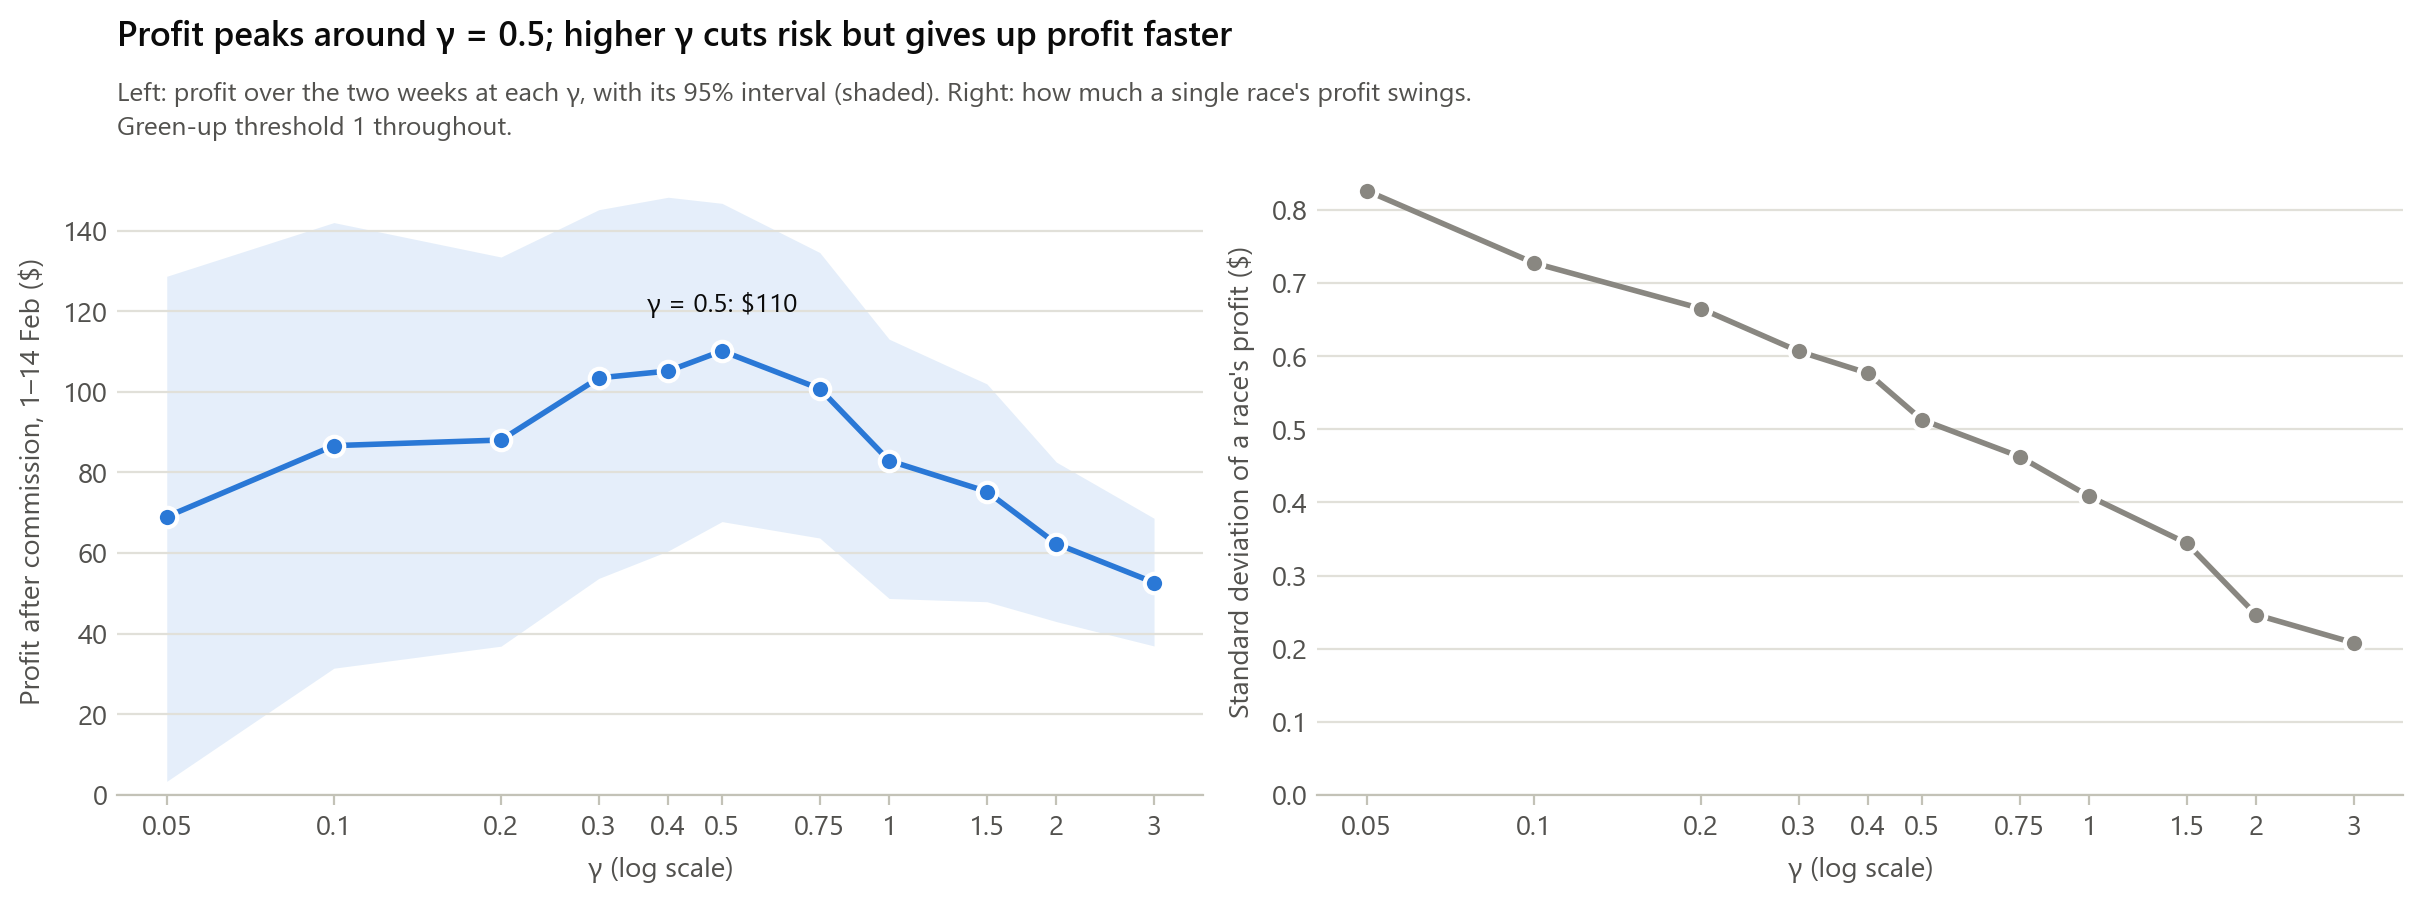

In [5]:
fig, (left, right) = plt.subplots(1, 2, figsize=(12, 4.4), layout="constrained")

left.fill_between(GAMMAS, summary["95% CI low"], summary["95% CI high"], color=BLUE, alpha=0.12, lw=0)
left.plot(GAMMAS, summary["profit"], "-o", color=BLUE)
left.axhline(0, color=LIGHT, lw=1)
left.annotate(f"γ = {best:g}: ${summary.loc[best, 'profit']:.0f}", (best, summary.loc[best, "profit"]),
              xytext=(0, 12), textcoords="offset points", ha="center", va="bottom", fontsize=9.5)
left.set(ylabel="Profit after commission, 1–14 Feb ($)", ylim=(0, None))

right.plot(GAMMAS, summary["sd per race"], "-o", color=GREY)
right.set(ylabel="Standard deviation of a race's profit ($)", ylim=(0, None))

for ax in (left, right):
    gamma_axis(ax)
titles(left, f"Profit peaks around γ = {best:g}; higher γ cuts risk but gives up profit faster",
       "Left: profit over the two weeks at each γ, with its 95% interval (shaded). "
       "Right: how much a single race's profit swings.\nGreen-up threshold 1 throughout.")
plt.show()

**What this shows**

- **There is a clear peak, and it's broad.** Profit rises from γ = 0.05 to a peak at γ = 0.5 and falls away after it. Between 0.3 and 0.75 the differences are a few dollars, well inside the paired intervals, so those values are effectively tied. γ = 0.5 sits in the middle of that flat top.
- **Too much risk aversion costs money.** From γ = 1 upwards, profit is clearly lower than at the peak: the paired intervals stay below zero. A large γ quotes so wide early in the window that it barely trades (about half as many races at γ = 3 as at γ = 0.5).
- **Too little isn't clearly worse, but it's riskier.** Below 0.3 profit is lower, though the intervals overlap with the peak's. What's certain is that a race's profit swings much more: at γ = 0.05 the typical swing is about 1.6 times that at γ = 0.5. Inventory builds up and has to be flattened at $T$.
- **Risk-adjusted, γ hardly matters.** The daily Sharpe ratio is between about 1.1 and 1.4 for every γ from 0.1 up, and with only 15 days that range is within noise. Higher γ trades profit for lower risk at about the same rate, so the profit peak decides.

**γ = 0.5.**

## Step 3: Choosing the green-up threshold

Flattening a position at $T$ costs money: we cross the spread, often a tick or two through it. Not flattening means betting the position on the race result. The threshold decides where that line sits.

Holding a position to the result adds a bet on that race's outcome. That bet is roughly fair on average, but very noisy: a runner priced at 3.0 wins a third of the time. So a threshold should only count as better if it helps **consistently across γ**, not just in total at one γ. The map below shows every combination.

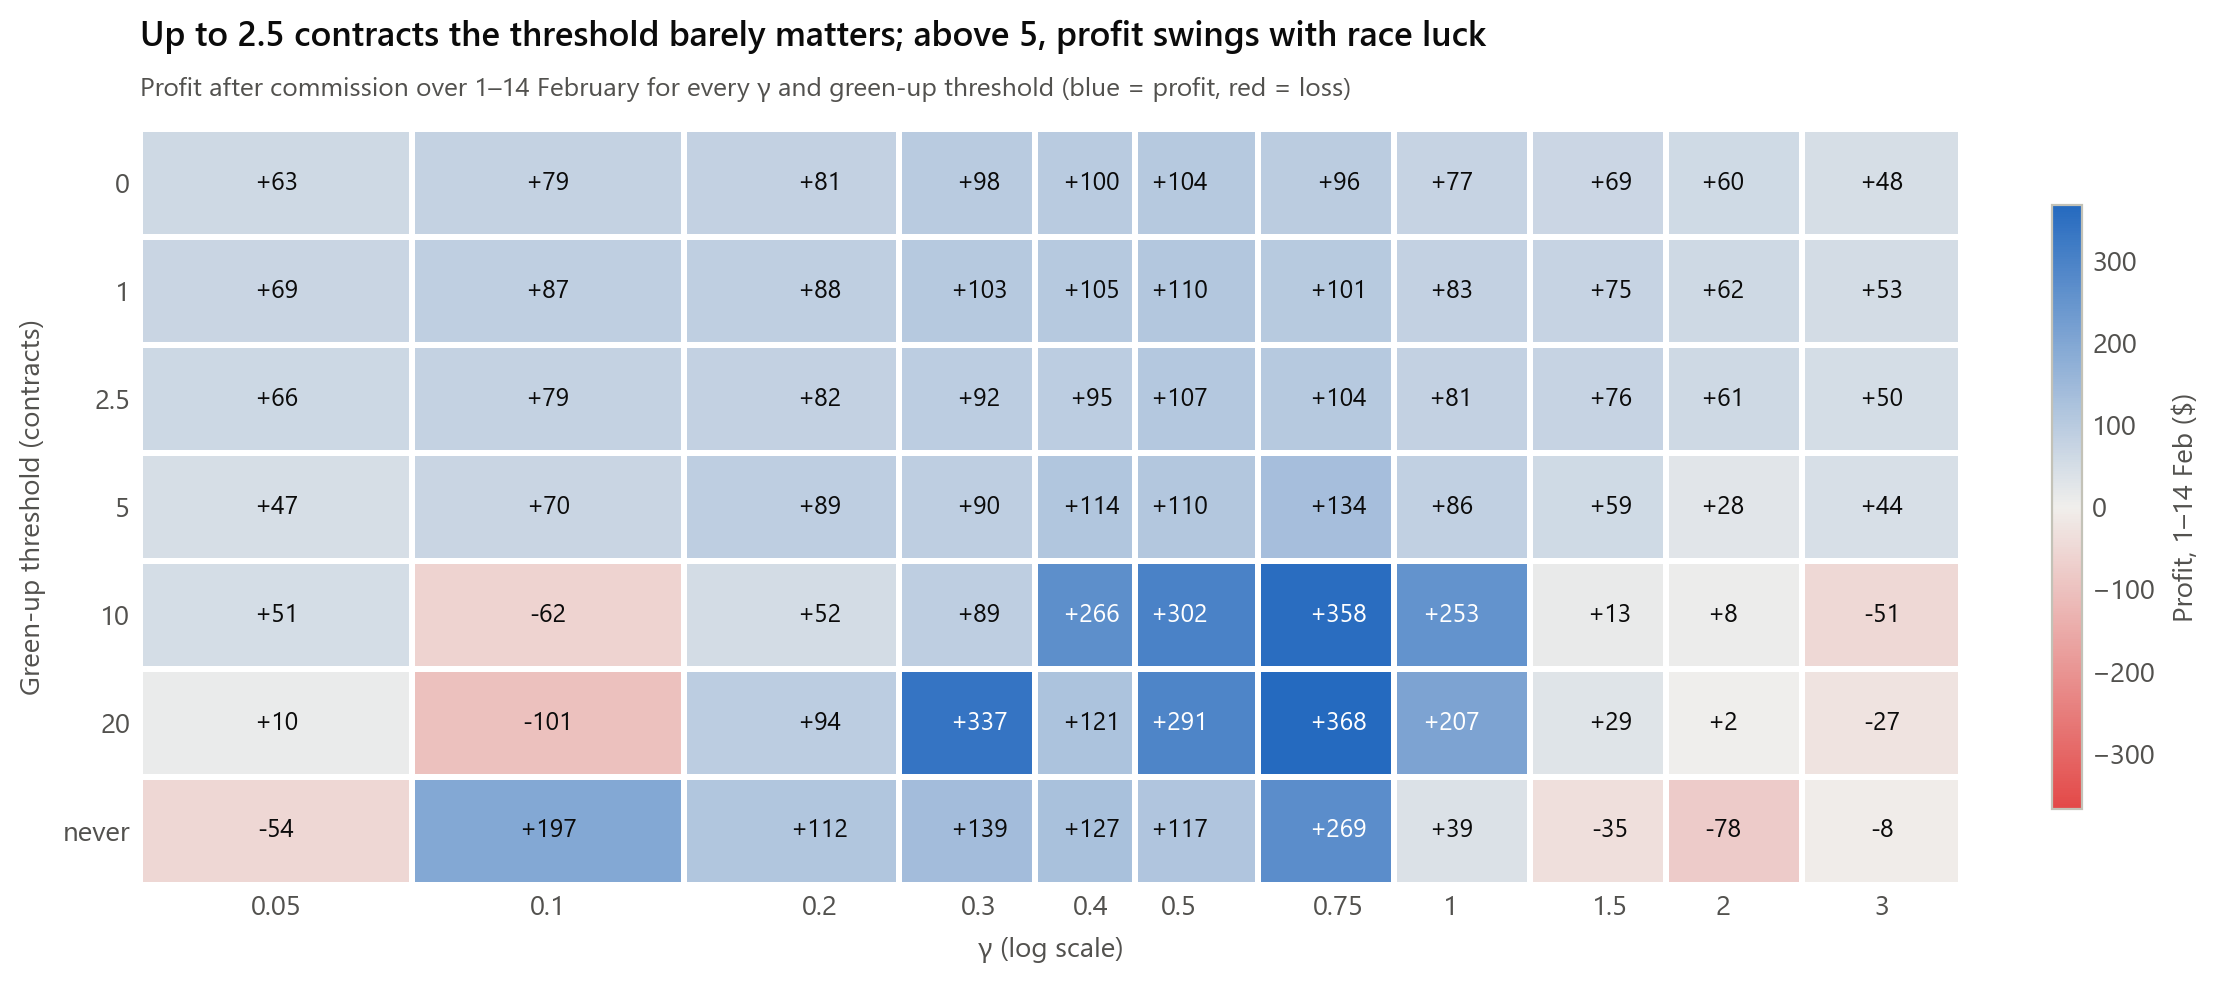

In [6]:
grid = pd.DataFrame({g: [profit[(g, t)].sum() for t in THRESHOLDS] for g in GAMMAS}, index=THRESHOLDS)

# gamma cells sized on a log scale: each cell spans halfway (in log terms) to its neighbours
logs = np.log10(GAMMAS)
edges = 10 ** np.concatenate([[logs[0] - (logs[1] - logs[0]) / 2], (logs[:-1] + logs[1:]) / 2,
                              [logs[-1] + (logs[-1] - logs[-2]) / 2]])
rows = np.arange(len(THRESHOLDS) + 1)
DIVERGING = LinearSegmentedColormap.from_list("loss_profit", ["#e34948", "#f0efec", "#256abf"])
limit = np.abs(grid.to_numpy()).max()

fig, ax = plt.subplots(figsize=(11, 4.8), layout="constrained")
image = ax.pcolormesh(edges, rows, grid.to_numpy(), cmap=DIVERGING, vmin=-limit, vmax=limit,
                      edgecolors="white", linewidth=2)
for r, t in enumerate(THRESHOLDS):
    for g in GAMMAS:
        value = grid.loc[t, g]
        ax.text(g, r + 0.5, f"{value:+.0f}", ha="center", va="center", fontsize=9,
                color="white" if abs(value) > 0.55 * limit else INK)
ax.set_xscale("log")
ax.xaxis.set_major_locator(FixedLocator(GAMMAS))
ax.xaxis.set_minor_locator(NullLocator())
ax.set_xticklabels([f"{g:g}" for g in GAMMAS])
ax.set_yticks(rows[:-1] + 0.5, [threshold_name(t) for t in THRESHOLDS])
ax.set_ylim(len(THRESHOLDS), 0)                   # threshold 0 at the top
ax.tick_params(length=0)
ax.grid(False)
ax.spines["bottom"].set_visible(False)
ax.set(xlabel="γ (log scale)", ylabel="Green-up threshold (contracts)")
fig.colorbar(image, ax=ax, shrink=0.8, label="Profit, 1–14 Feb ($)")
titles(ax, "Up to 2.5 contracts the threshold barely matters; above 5, profit swings with race luck",
       "Profit after commission over 1–14 February for every γ and green-up threshold "
       "(blue = profit, red = loss)")
plt.show()

The top three rows change smoothly from one γ to the next, as profit should when a setting changes a little. From a threshold of 5 down, neighbouring cells jump by hundreds of dollars in both directions. That isn't the threshold doing anything clever. It's which races happened to be won by the runners we were left holding.

To separate the two, here is each threshold against flattening everything, at γ = 0.5: the change in profit with a paired 95% interval, how much a race's profit swings, and in how many of the 11 γ columns the threshold beats flattening everything.

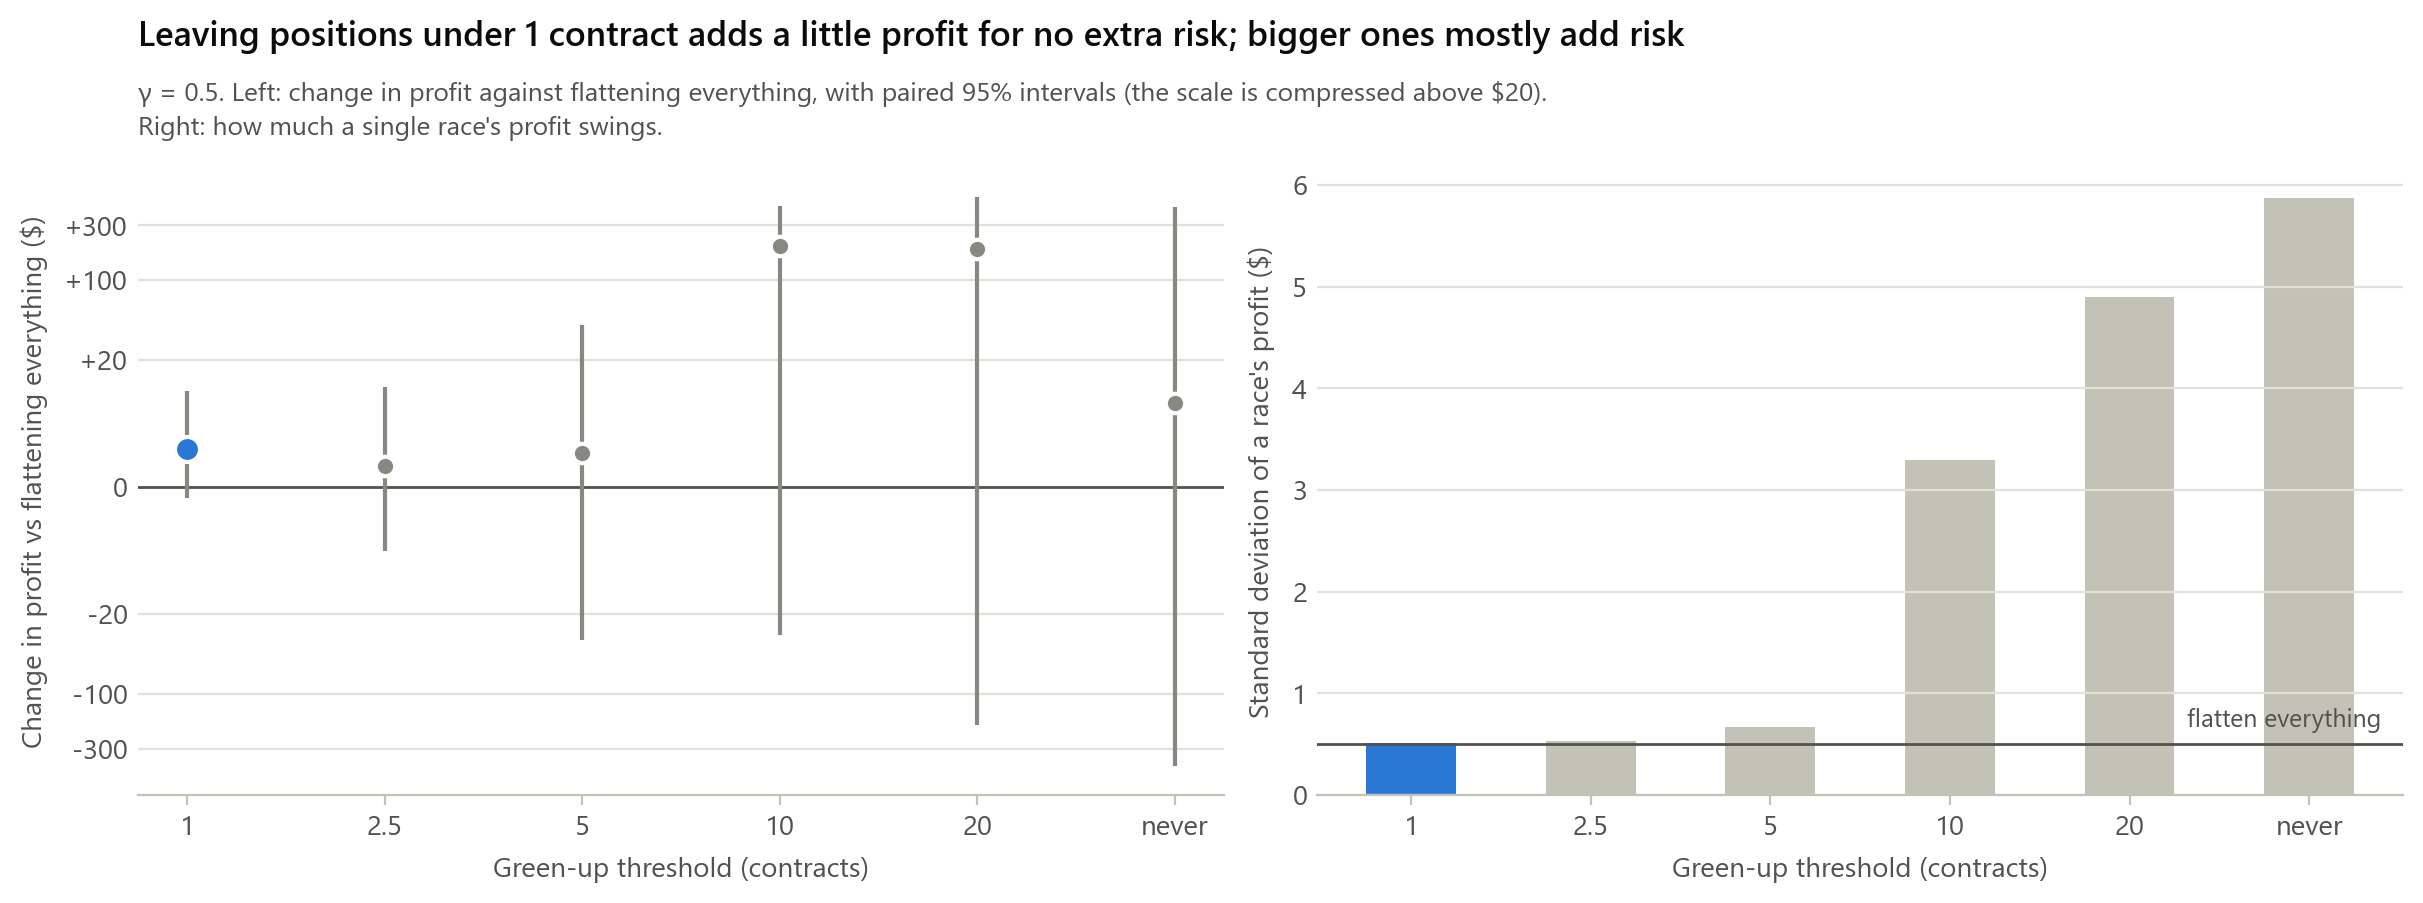

,change in profit,95% CI low,95% CI high,sd per race,beats flattening everything
threshold,,,,,
1,5.94,-1.71,15.04,0.51,11/11 γ
2.5,3.22,-10.10,15.73,0.53,9/11 γ
5,5.29,-33.45,39.96,0.66,5/11 γ
10,197.35,-30.43,444.56,3.29,4/11 γ
20,186.80,-186.31,533.83,4.90,6/11 γ
never,13.22,-428.30,434.30,5.87,6/11 γ


In [7]:
base = (best, 0)
by_threshold = []
for t in THRESHOLDS[1:]:
    low, high = interval(boot[(best, t)] - boot[base])
    by_threshold.append({"threshold": threshold_name(t),
                         "change in profit": profit[(best, t)].sum() - profit[base].sum(),
                         "95% CI low": low, "95% CI high": high,
                         "sd per race": profit[(best, t)].std(),
                         "beats flattening everything": f"{sum(grid.loc[t, g] > grid.loc[0, g] for g in GAMMAS)}/{len(GAMMAS)} γ"})
by_threshold = pd.DataFrame(by_threshold).set_index("threshold")

fig, (left, right) = plt.subplots(1, 2, figsize=(12, 4.4), layout="constrained")
x = np.arange(len(by_threshold))
change = by_threshold["change in profit"].to_numpy()
left.axhline(0, color=INK_2, lw=1)
left.errorbar(x, change, yerr=[change - by_threshold["95% CI low"], by_threshold["95% CI high"] - change],
              fmt="none", ecolor=GREY, elinewidth=1.5)
left.plot(x, change, "o", color=GREY)
left.plot(x[0], change[0], "o", color=BLUE, ms=9)
left.set(ylabel=f"Change in profit vs flattening everything ($)")
left.set_yscale("symlog", linthresh=20)           # small changes stay visible next to the huge intervals
ticks = [-300, -100, -20, 0, 20, 100, 300]
left.yaxis.set_major_locator(FixedLocator(ticks))
left.yaxis.set_minor_locator(NullLocator())
left.set_yticklabels([f"{t:+,d}" if t else "0" for t in ticks])
right.bar(x, by_threshold["sd per race"], width=0.5, color=[BLUE] + [LIGHT] * (len(x) - 1))
right.axhline(profit[base].std(), color=INK_2, lw=1)
right.annotate("flatten everything", (len(x) - 0.6, profit[base].std()), xytext=(0, 4), textcoords="offset points",
               ha="right", va="bottom", fontsize=9, color=INK_2)
right.set(ylabel="Standard deviation of a race's profit ($)")
for ax in (left, right):
    ax.set_xticks(x, by_threshold.index)
    ax.set_xlabel("Green-up threshold (contracts)")
titles(left, "Leaving positions under 1 contract adds a little profit for no extra risk; bigger ones mostly add risk",
       f"γ = {best:g}. Left: change in profit against flattening everything, with paired 95% intervals "
       "(the scale is compressed above $20).\nRight: how much a single race's profit swings.")
plt.show()

by_threshold.round(2)

**What this shows**

- **1 contract is the only threshold that helps every time.** It beats flattening everything in all 11 γ columns. The gain is small (about $6 over two weeks at γ = 0.5 by the shortcut, and $3 in the real backtest: $106.87 against $104.21), but it comes with no extra risk: a race's profit swings exactly as much as before. These are tiny positions, where flattening means crossing the spread to remove almost no risk.
- **2.5 helps more often than not, but it's less reliable.** It beats flattening everything for 9 of the 11 γ, and its interval at γ = 0.5 is centred close to zero.
- **From 5 upwards, it's a lottery.** These thresholds beat flattening everything in only about half the γ columns. The typical swing in a race's profit is 6 to 11 times larger, and the intervals run to hundreds of dollars either side of zero. The large totals in the map are race luck, and a strategy that relies on it would be betting on results, not making markets.

**Threshold: 1 contract.**

## Step 4: The chosen settings over the two weeks

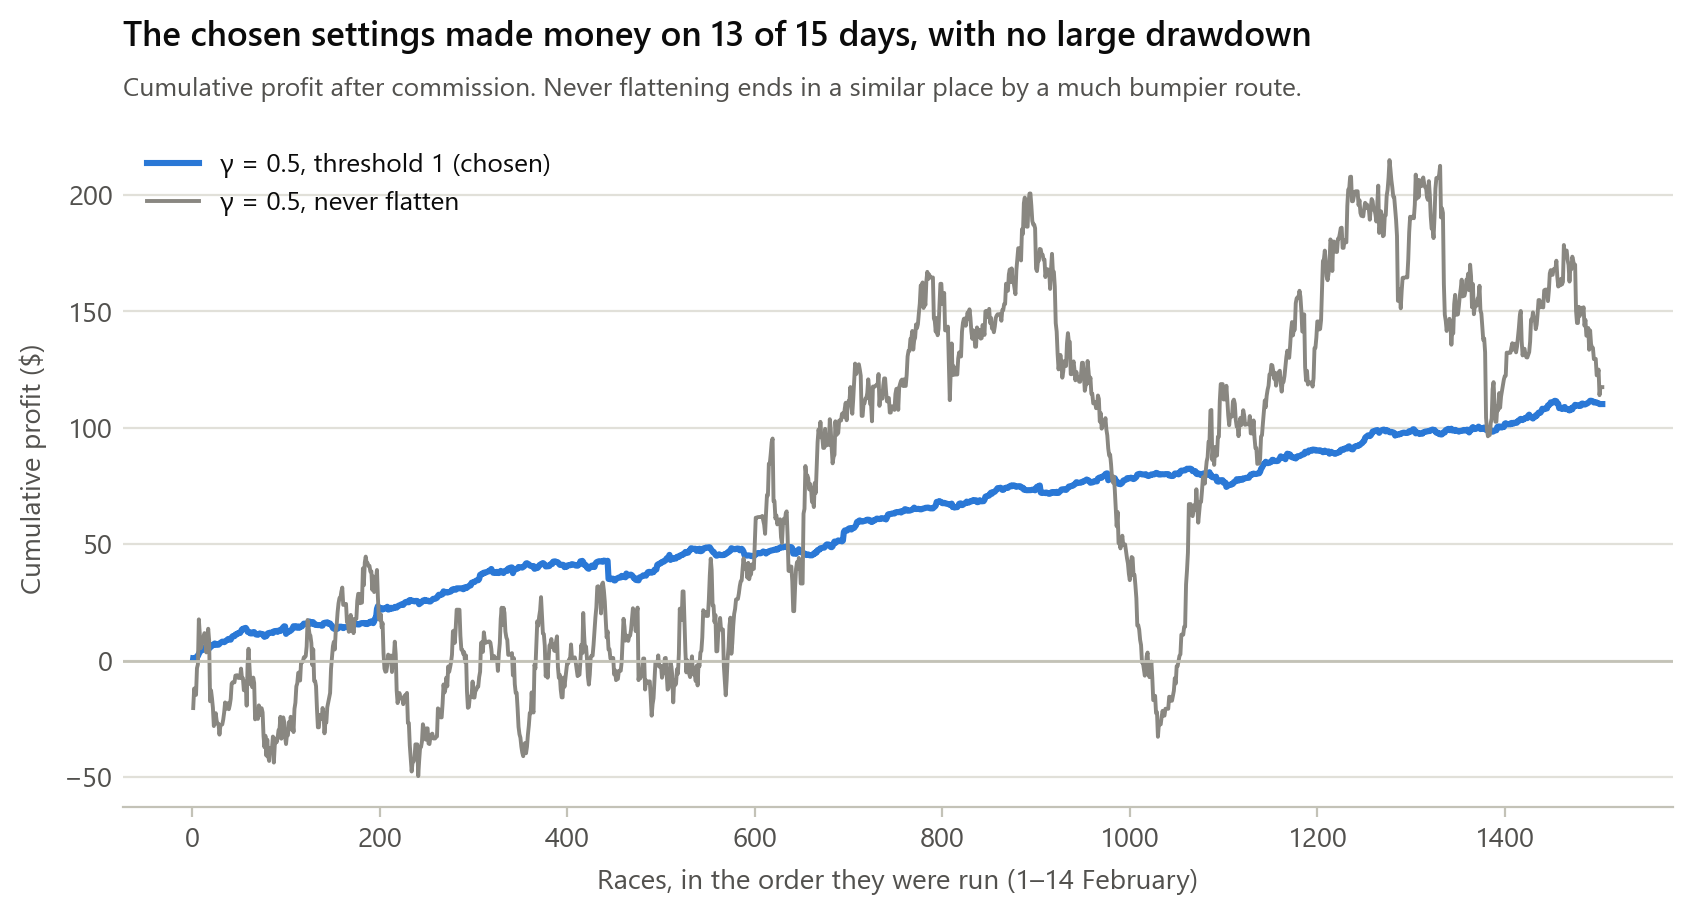

,"γ = 0.5, threshold 1"
profit ($),110.157086
races traded,1331
profit per race traded ($),0.082763
profitable days,13 of 15
worst day ($),-3.395124
largest drawdown ($),8.525264


In [8]:
chosen = (best, CHOSEN_THRESHOLD)
lines = {f"γ = {best:g}, threshold {CHOSEN_THRESHOLD} (chosen)": (chosen, BLUE, 2.2),
         f"γ = {best:g}, never flatten": ((best, np.inf), GREY, 1.4)}

order = first_fill.reindex(RACES).sort_values().index           # races in the order they were run
fig, ax = plt.subplots(figsize=(10, 4.4))
for label, (setting, colour, width) in lines.items():
    ax.plot(np.arange(1, len(order) + 1), profit.loc[order, setting].cumsum().to_numpy(), color=colour, lw=width,
            label=label)
ax.axhline(0, color=LIGHT, lw=1)
ax.set(xlabel="Races, in the order they were run (1–14 February)", ylabel="Cumulative profit ($)")
legend(ax, loc="upper left")
daily = profit[chosen].groupby(day).sum()
titles(ax, f"The chosen settings made money on {(daily > 0).sum()} of {len(daily)} days, with no large drawdown",
       "Cumulative profit after commission. Never flattening ends in a similar place by a much bumpier route.")
plt.show()

cumulative = profit.loc[order, chosen].cumsum()
pd.Series({"profit ($)": profit[chosen].sum(),
           "races traded": summary.loc[best, "races traded"],
           "profit per race traded ($)": profit[chosen].sum() / summary.loc[best, "races traded"],
           "profitable days": f"{(daily > 0).sum()} of {len(daily)}",
           "worst day ($)": daily.min(),
           "largest drawdown ($)": (cumulative.cummax() - cumulative).max()}).to_frame("γ = 0.5, threshold 1")

## Decision

| Setting | Value |
|---|---|
| `gamma` | **0.5** |
| `greenup_min_units` | **1** |

γ = 0.5 sits in the middle of the profit peak, with 0.3 to 0.75 effectively tied around it. A green-up threshold of 1 contract is the only one that beats flattening everything for every γ, without adding risk. The real backtest with both settings made **$106.87** after commission over 1–14 February.